<a href="https://colab.research.google.com/github/PRADYuMNAV1/llm-identification/blob/main/LLM_identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install datasets

In [2]:
import random
from collections import Counter

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

dataset = load_dataset("openbmb/UltraFeedback", split="train")

print("Number of prompts:", len(dataset))
print("Columns:", dataset.column_names)

model_counts = Counter(
    completion["model"]
    for row in dataset
    for completion in row["completions"]
)

print("\nResponses per model:")
for model, count in model_counts.most_common():
    print(f"{model}: {count:,}")

Device: cuda


README.md:   0%|          | 0.00/15.4k [00:00<?, ?B/s]

evol_instruct.jsonl: reconstructing file:   0%|          |  0.00B /  168MB            

evol_instruct.jsonl: downloading bytes:           |  0.00B            

false_qa.jsonl: reconstructing file:   0%|          |  0.00B / 25.9MB            

...

truthful_qa.jsonl:   0%|          | 0.00/9.99M [00:00<?, ?B/s]

ultrachat.jsonl: reconstructing file:   0%|          |  0.00B /  182MB            

ultrachat.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/63967 [00:00<?, ? examples/s]

Number of prompts: 63967
Columns: ['source', 'instruction', 'models', 'completions', 'correct_answers', 'incorrect_answers']

Responses per model:
wizardlm-13b: 16,804
llama-2-7b-chat: 16,773
vicuna-33b: 16,753
ultralm-65b: 16,681
llama-2-13b-chat: 16,638
wizardlm-7b: 16,596
ultralm-13b: 16,583
llama-2-70b-chat: 16,579
alpaca-7b: 16,576
falcon-40b-instruct: 16,568
mpt-30b-chat: 16,561
gpt-3.5-turbo: 16,561
wizardlm-70b: 16,529
gpt-4: 16,518
starchat: 13,977
bard: 8,333
pythia-12b: 834


In [3]:
import re
from sklearn.model_selection import train_test_split

SELECTED_MODELS = [
    "gpt-4",
    "llama-2-70b-chat",
    "falcon-40b-instruct",
]

# Extract only the prompt, actual response, and relevant metadata.
# GPT-4's ratings and feedback are not classifier inputs.
records = []

for row in dataset:
    prompt = row["instruction"]

    if not isinstance(prompt, str) or not prompt.strip():
        continue

    for completion in row["completions"]:
        model = completion["model"]

        if model not in SELECTED_MODELS:
            continue

        response = completion["response"]

        if not isinstance(response, str) or not response.strip():
            continue

        records.append({
            "LLM_name": model,
            "LLM_Input": prompt.strip(),
            "LLM_output": response.strip(),
            "source": row["source"],
        })

df = pd.DataFrame(records)

# Normalize prompts only for grouping; preserve the original input text.
df["prompt_group"] = df["LLM_Input"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip().casefold()
)

# Keep one response per model for each normalized prompt.
df = df.drop_duplicates(
    subset=["prompt_group", "LLM_name"]
).reset_index(drop=True)

# Split unique prompts first so the same prompt cannot cross splits.
prompt_groups = sorted(df["prompt_group"].unique())

train_groups, remaining_groups = train_test_split(
    prompt_groups,
    test_size=0.30,
    random_state=SEED,
)

val_groups, test_groups = train_test_split(
    remaining_groups,
    test_size=0.50,
    random_state=SEED,
)

def make_balanced_split(groups, examples_per_model):
    subset = df[df["prompt_group"].isin(groups)]

    counts = subset["LLM_name"].value_counts()
    available = min(counts.get(model, 0) for model in SELECTED_MODELS)

    if available < examples_per_model:
        raise ValueError(
            f"Need {examples_per_model} examples per model, "
            f"but the smallest class has {available}."
        )

    pieces = [
        subset[subset["LLM_name"] == model].sample(
            n=examples_per_model,
            random_state=SEED,
        )
        for model in SELECTED_MODELS
    ]

    return (
        pd.concat(pieces)
        .sample(frac=1, random_state=SEED)
        .reset_index(drop=True)
    )

train_df = make_balanced_split(train_groups, 2100)
val_df = make_balanced_split(val_groups, 450)
test_df = make_balanced_split(test_groups, 450)

# Verify that no normalized prompt appears in multiple splits.
train_prompts = set(train_df["prompt_group"])
val_prompts = set(val_df["prompt_group"])
test_prompts = set(test_df["prompt_group"])

assert train_prompts.isdisjoint(val_prompts)
assert train_prompts.isdisjoint(test_prompts)
assert val_prompts.isdisjoint(test_prompts)

counts_table = pd.DataFrame({
    "Training": train_df["LLM_name"].value_counts(),
    "Validation": val_df["LLM_name"].value_counts(),
    "Testing": test_df["LLM_name"].value_counts(),
}).reindex(SELECTED_MODELS)

print(counts_table)
print("\nTotal examples:", len(train_df) + len(val_df) + len(test_df))
print("Verified: no prompt overlap between splits.")

# Inspect a short preview.
display(train_df[["LLM_name", "LLM_Input", "LLM_output"]].head(3))

                     Training  Validation  Testing
LLM_name                                          
gpt-4                    2100         450      450
llama-2-70b-chat         2100         450      450
falcon-40b-instruct      2100         450      450

Total examples: 9000
Verified: no prompt overlap between splits.


,LLM_name,LLM_Input,LLM_output
0,gpt-4,Expand the functionality of a Python function ...,"To accomplish this, you can modify the existin..."
1,gpt-4,What happens if you place a mirror by your bed?,Placing a mirror by your bed may have differen...
2,gpt-4,"As an HR manager, you have noticed a lack of d...",While I cannot create a PowerPoint presentatio...


In [4]:
from torch.utils.data import Dataset, DataLoader

def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

# Build the vocabulary from training data only.
token_counts = Counter()
for column in ["LLM_Input", "LLM_output"]:
    for text in train_df[column]:
        token_counts.update(tokenize(text))

vocab = {"<PAD>": 0, "<UNK>": 1, "<SEP>": 2}
for token, _ in token_counts.most_common(19997):
    if token not in vocab:
        vocab[token] = len(vocab)

label_to_id = {
    model: index for index, model in enumerate(SELECTED_MODELS)
}

def encode(text):
    return [vocab.get(token, 1) for token in tokenize(text)]

class LLMTextDataset(Dataset):
    def __init__(self, frame, mode):
        self.examples = []

        for row in frame.to_dict("records"):
            if mode == "input":
                ids = encode(row["LLM_Input"])[:128]
            elif mode == "output":
                ids = encode(row["LLM_output"])[:256]
            elif mode == "combined":
                ids = (
                    encode(row["LLM_Input"])[:128]
                    + [2]
                    + encode(row["LLM_output"])[:256]
                )
            else:
                raise ValueError(f"Unknown mode: {mode}")

            self.examples.append(
                (ids or [1], label_to_id[row["LLM_name"]])
            )

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]

def collate_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sequences])

    inputs = torch.zeros(
        len(batch), max(5, int(lengths.max())), dtype=torch.long
    )
    for index, sequence in enumerate(sequences):
        inputs[index, :len(sequence)] = torch.tensor(sequence)

    return inputs, lengths, torch.tensor(labels)

def make_loaders(mode):
    return {
        split: DataLoader(
            LLMTextDataset(frame, mode),
            batch_size=64,
            shuffle=(split == "train"),
            collate_fn=collate_batch,
        )
        for split, frame in {
            "train": train_df,
            "val": val_df,
            "test": test_df,
        }.items()
    }

print("Vocabulary size:", len(vocab))
print("Labels:", label_to_id)
print("Text preparation complete.")

Vocabulary size: 20000
Labels: {'gpt-4': 0, 'llama-2-70b-chat': 1, 'falcon-40b-instruct': 2}
Text preparation complete.


In [5]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

class TextCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(
            len(vocab), 128, padding_idx=0
        )
        self.convs = nn.ModuleList([
            nn.Conv1d(128, 64, kernel_size=k)
            for k in [3, 4, 5]
        ])
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(64 * 3, 3)

    def forward(self, inputs, lengths):
        embedded = self.embedding(inputs).transpose(1, 2)
        pooled = []

        for conv in self.convs:
            features = torch.relu(conv(embedded))

            # Exclude convolution windows extending into padding.
            width = conv.kernel_size[0]
            valid_windows = (lengths - width + 1).clamp(min=0)
            positions = torch.arange(
                features.size(2), device=inputs.device
            )
            mask = positions[None, :] < valid_windows[:, None]

            features = features.masked_fill(
                ~mask[:, None, :], float("-inf")
            )
            values = features.max(dim=2).values

            # Very short texts may have no valid window.
            values = torch.where(
                valid_windows[:, None] > 0,
                values,
                torch.zeros_like(values),
            )
            pooled.append(values)

        combined = torch.cat(pooled, dim=1)
        return self.classifier(self.dropout(combined))


class TextLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(
            len(vocab), 128, padding_idx=0
        )
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            batch_first=True,
        )
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(128, 3)

    def forward(self, inputs, lengths):
        embedded = self.embedding(inputs)

        # Packing prevents padding from affecting the final state.
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )
        _, (hidden, _) = self.lstm(packed)

        return self.classifier(self.dropout(hidden[-1]))


# Check that both models produce one score per class.
loaders = make_loaders("output")
inputs, lengths, labels = next(iter(loaders["train"]))

for Model in [TextCNN, TextLSTM]:
    model = Model().to(device)
    with torch.no_grad():
        scores = model(inputs.to(device), lengths.to(device))
    print(Model.__name__, "output shape:", tuple(scores.shape))

del model

TextCNN output shape: (64, 3)
TextLSTM output shape: (64, 3)


In [6]:
import copy
import time
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

EPOCHS = 5
results = []
confusion_matrices = {}

def evaluate(model, loader):
    model.eval()
    actual, predicted = [], []

    with torch.no_grad():
        for inputs, lengths, labels in loader:
            scores = model(
                inputs.to(device), lengths.to(device)
            )
            predicted.extend(scores.argmax(dim=1).cpu().tolist())
            actual.extend(labels.tolist())

    return {
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual, predicted,
            labels=list(range(3)),
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            actual, predicted, labels=list(range(3))
        ),
    }

for model_name, Model in [("CNN", TextCNN), ("LSTM", TextLSTM)]:
    for mode in ["input", "output", "combined"]:
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        loaders = make_loaders(mode)
        model = Model().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        criterion = nn.CrossEntropyLoss()

        best_f1 = -1
        best_state = None
        best_epoch = None
        start = time.time()

        print(f"\n--- {model_name}: {mode} ---", flush=True)

        for epoch in range(1, EPOCHS + 1):
            model.train()
            total_loss = 0

            for inputs, lengths, labels in loaders["train"]:
                inputs = inputs.to(device)
                lengths = lengths.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()
                scores = model(inputs, lengths)
                loss = criterion(scores, labels)
                loss.backward()

                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

                total_loss += loss.item() * labels.size(0)

            validation = evaluate(model, loaders["val"])

            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Loss: {total_loss / len(train_df):.4f} | "
                f"Val accuracy: {validation['accuracy']:.3f} | "
                f"Val macro F1: {validation['macro_f1']:.3f}",
                flush=True,
            )

            if validation["macro_f1"] > best_f1:
                best_f1 = validation["macro_f1"]
                best_epoch = epoch
                best_state = copy.deepcopy(model.state_dict())

        model.load_state_dict(best_state)
        test = evaluate(model, loaders["test"])

        results.append({
            "Model": model_name,
            "Input": mode,
            "Best epoch": best_epoch,
            "Validation macro F1": best_f1,
            "Test accuracy": test["accuracy"],
            "Test macro F1": test["macro_f1"],
        })

        confusion_matrices[(model_name, mode)] = test["confusion_matrix"]

        print(
            f"Test accuracy: {test['accuracy']:.3f} | "
            f"Test macro F1: {test['macro_f1']:.3f} | "
            f"Time: {(time.time() - start) / 60:.1f} minutes",
            flush=True,
        )

        del model, optimizer, best_state
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
display(results_df.round(4))


--- CNN: input ---
Epoch 1/5 | Loss: 1.1858 | Val accuracy: 0.342 | Val macro F1: 0.340
Epoch 2/5 | Loss: 1.0657 | Val accuracy: 0.352 | Val macro F1: 0.333
Epoch 3/5 | Loss: 1.0049 | Val accuracy: 0.336 | Val macro F1: 0.317
Epoch 4/5 | Loss: 0.9521 | Val accuracy: 0.341 | Val macro F1: 0.272
Epoch 5/5 | Loss: 0.8918 | Val accuracy: 0.345 | Val macro F1: 0.324
Test accuracy: 0.320 | Test macro F1: 0.320 | Time: 0.1 minutes

--- CNN: output ---
Epoch 1/5 | Loss: 0.9247 | Val accuracy: 0.713 | Val macro F1: 0.714
Epoch 2/5 | Loss: 0.6780 | Val accuracy: 0.733 | Val macro F1: 0.730
Epoch 3/5 | Loss: 0.5707 | Val accuracy: 0.774 | Val macro F1: 0.775
Epoch 4/5 | Loss: 0.5009 | Val accuracy: 0.777 | Val macro F1: 0.778
Epoch 5/5 | Loss: 0.4396 | Val accuracy: 0.787 | Val macro F1: 0.787
Test accuracy: 0.781 | Test macro F1: 0.781 | Time: 0.1 minutes

--- CNN: combined ---
Epoch 1/5 | Loss: 1.0073 | Val accuracy: 0.690 | Val macro F1: 0.694
Epoch 2/5 | Loss: 0.7425 | Val accuracy: 0.751 | 

,Model,Input,Best epoch,Validation macro F1,Test accuracy,Test macro F1
0,CNN,input,1,0.3402,0.3200,0.3197
1,CNN,output,5,0.7875,0.7815,0.7815
2,CNN,combined,5,0.7672,0.7474,0.7457
3,LSTM,input,5,0.3468,0.3319,0.3280
4,LSTM,output,4,0.6540,0.6533,0.6521
5,LSTM,combined,4,0.6546,0.6474,0.6469


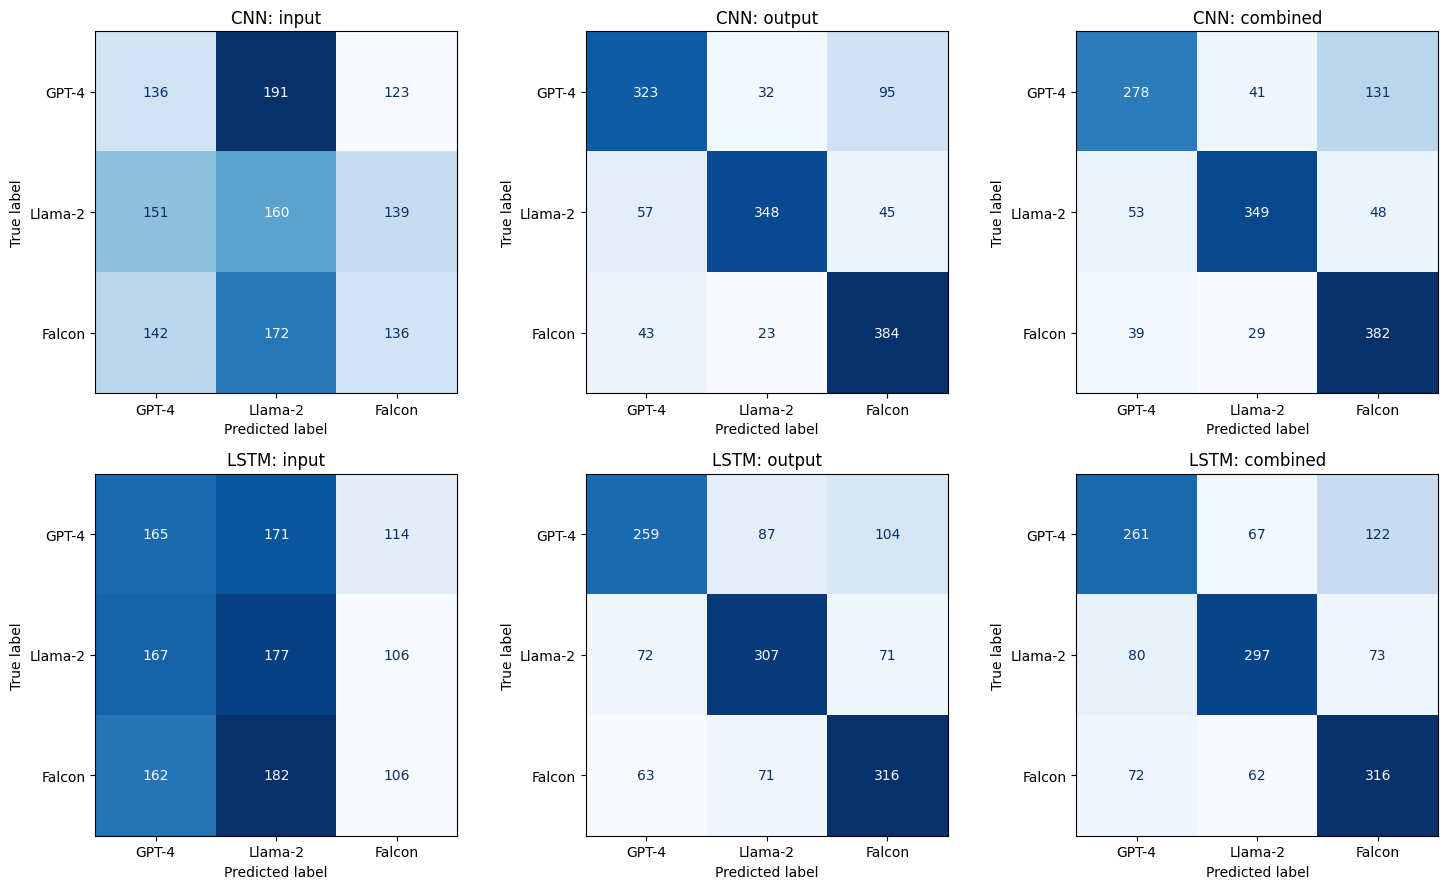

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

short_labels = ["GPT-4", "Llama-2", "Falcon"]

for row, model_name in enumerate(["CNN", "LSTM"]):
    for col, mode in enumerate(["input", "output", "combined"]):
        ConfusionMatrixDisplay(
            confusion_matrix=confusion_matrices[(model_name, mode)],
            display_labels=short_labels,
        ).plot(
            ax=axes[row, col],
            cmap="Blues",
            colorbar=False,
            values_format="d",
        )
        axes[row, col].set_title(f"{model_name}: {mode}")

plt.tight_layout()
plt.show()